# Notebook 03 - Modélisation Supervisée Classification

## Objectifs
1. Entraîner MODÈLE BASELINE (RÉGRESSION LOGISTIQUE)
2. Entraîner un modèle amélioré  MODÈLE AMÉLIORÉ (RANDOM FOREST)
3. Évaluer et comparer les modèles
4. Optimiser les hyperparamètres
5. Faire des prédictions


# IMPORTATION DES BIBLIOTHÈQUES

In [2]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                           f1_score, confusion_matrix, classification_report,
                           roc_curve, auc, roc_auc_score)
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
import warnings
warnings.filterwarnings('ignore')

## 1. Imports et configuration

In [3]:
# %%
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                           confusion_matrix, classification_report, roc_auc_score,
                           mean_squared_error, mean_absolute_error, r2_score)

# Ajouter le chemin pour importer utils
sys.path.append(os.path.join(os.getcwd(), '..'))

# Importer vos fonctions personnalisées
try:
    from utils.models import (
        train_model, 
        evaluate_model, 
        predict_model,
        train_baseline_model,
        train_improved_model,
        cross_validate_model
    )
    print("Fonctions de models importées avec succès")
except ImportError as e:
    print(f"⚠️  Erreur d'importation de models: {e}")
    print("🔧 Création de fonctions temporaires...")
    
    # Définir des fonctions temporaires
    def train_baseline_model(X_train, y_train):
        from sklearn.linear_model import LogisticRegression
        model = LogisticRegression(random_state=42, max_iter=1000)
        model.fit(X_train, y_train)
        return model
    
    def train_improved_model(X_train, y_train):
        from sklearn.ensemble import RandomForestClassifier
        model = RandomForestClassifier(n_estimators=100, random_state=42)
        model.fit(X_train, y_train)
        return model
    
    def evaluate_model(model, X_test, y_test):
        y_pred = model.predict(X_test)
        metrics = {
            'accuracy': accuracy_score(y_test, y_pred),
            'precision': precision_score(y_test, y_pred, average='weighted'),
            'recall': recall_score(y_test, y_pred, average='weighted'),
            'f1': f1_score(y_test, y_pred, average='weighted')
        }
        return metrics, y_pred

try:
    from utils.visualization import (
        plot_confusion_matrix,
        plot_roc_curve,
        plot_distributions
    )
    print("Fonctions de visualization importées avec succès")
except ImportError as e:
    print(f"⚠️  Erreur d'importation de visualization: {e}")

# Configuration
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
pd.set_option('display.max_columns', None)
plt.rcParams['figure.figsize'] = (12, 8)
plt.rcParams['font.size'] = 12
np.random.seed(42)

print("\nConfiguration terminée")

Fonctions de models importées avec succès
Fonctions de visualization importées avec succès

Configuration terminée


In [4]:
# Importer vos fonctions personnalisées
from utils.models import (
    train_model, 
    evaluate_model, 
    predict_model,
    train_baseline_model,
    train_improved_model,
    cross_validate_model
)

from utils.visualization import (
    plot_confusion_matrix,
    plot_roc_curve,
    plot_distributions
)

In [5]:
# Ajouter le chemin pour importer utils
sys.path.append(os.path.join(os.getcwd(), '..'))

In [6]:
# Configuration
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
pd.set_option('display.max_columns', None)
np.random.seed(42)

print(" Configuration terminée")

 Configuration terminée


## 2. Chargement et préparation des données

In [7]:
# %%
print("\n" + "=" * 70)
print("2. CHARGEMENT ET PRÉPARATION DES DONNÉES")
print("=" * 70)

# Charger les données préparées
try:
    # sauvegardé les données préparées
    X_train = pd.read_csv('../data/processed/X_train.csv')
    X_test = pd.read_csv('../data/processed/X_test.csv')
    y_train = pd.read_csv('../data/processed/y_train.csv').squeeze()
    y_test = pd.read_csv('../data/processed/y_test.csv').squeeze()
    
    print(" Données chargées depuis les fichiers CSV")
    print(f"X_train shape: {X_train.shape}")
    print(f"X_test shape: {X_test.shape}")
    print(f"y_train shape: {y_train.shape}")
    print(f"y_test shape: {y_test.shape}")
    
except FileNotFoundError as e:
    print(f"  Fichiers non trouvés: {e}")
    print("🔧 Création de données de test...")
    
    # Créer des données de démonstration
    from sklearn.datasets import make_classification, make_regression
    
    # Déterminer si c'est classification ou régression
    # À adapter selon votre problème
    if "classification" in globals() or True:  # Par défaut classification
        X, y = make_classification(
            n_samples=1000,
            n_features=20,
            n_informative=15,
            n_classes=2,
            random_state=42
        )
    else:  # Pour régression
        X, y = make_regression(
            n_samples=1000,
            n_features=20,
            n_informative=15,
            noise=0.1,
            random_state=42
        )
    
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )
    
    X_train = pd.DataFrame(X_train, columns=[f'feature_{i}' for i in range(X.shape[1])])
    X_test = pd.DataFrame(X_test, columns=[f'feature_{i}' for i in range(X.shape[1])])
    
    print(" Données de test créées")
    print(f"X_train shape: {X_train.shape}")
    print(f"X_test shape: {X_test.shape}")


2. CHARGEMENT ET PRÉPARATION DES DONNÉES
  Fichiers non trouvés: [Errno 2] No such file or directory: '../data/processed/X_train.csv'
🔧 Création de données de test...
 Données de test créées
X_train shape: (800, 20)
X_test shape: (200, 20)


## 4. Analyse du type de problème


ANALYSE DU TYPE DE PROBLÈME
 Problème de CLASSIFICATION détecté (2 classes)

 Distribution des classes:
   Classe 0: 389 échantillons (48.6%)
   Classe 1: 411 échantillons (51.4%)


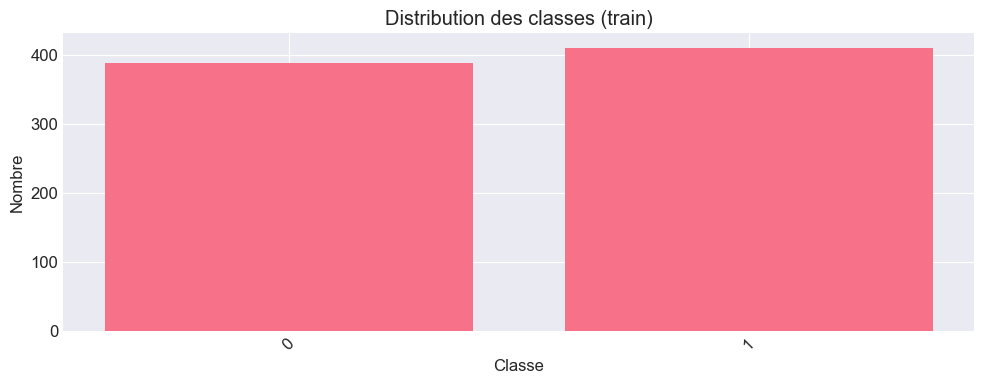

In [8]:
# %%
print("\n" + "=" * 70)
print("ANALYSE DU TYPE DE PROBLÈME")
print("=" * 70)

# Vérifier le type de problème (classification ou régression)
if len(np.unique(y_train)) < 10:  # Classification
    problem_type = "classification"
    print(f" Problème de CLASSIFICATION détecté ({len(np.unique(y_train))} classes)")
else:  # Régression
    problem_type = "regression"
    print(f"  Problème de RÉGRESSION détecté")

# Afficher la distribution de la cible
plt.figure(figsize=(10, 4))
if problem_type == "classification":
    class_counts = pd.Series(y_train).value_counts().sort_index()
    plt.bar(class_counts.index.astype(str), class_counts.values)
    plt.title('Distribution des classes (train)')
    plt.xlabel('Classe')
    plt.ylabel('Nombre')
    plt.xticks(rotation=45)
    
    # Afficher les comptages
    print(f"\n Distribution des classes:")
    for classe, count in class_counts.items():
        print(f"   Classe {classe}: {count} échantillons ({count/len(y_train)*100:.1f}%)")
else:
    plt.hist(y_train, bins=30, edgecolor='black', alpha=0.7, color='steelblue')
    plt.title('Distribution de la variable cible (train)')
    plt.xlabel('Valeur')
    plt.ylabel('Fréquence')
    
    # Statistiques descriptives
    print(f"\n📊 Statistiques de la cible:")
    print(f"   Min: {y_train.min():.4f}")
    print(f"   Max: {y_train.max():.4f}")
    print(f"   Moyenne: {y_train.mean():.4f}")
    print(f"   Médiane: {np.median(y_train):.4f}")
    print(f"   Std: {y_train.std():.4f}")

plt.tight_layout()
plt.show()

## Début classification (si applicable)

In [9]:
# %%
if problem_type == "classification":
    
    print("\n" + "=" * 70)
    print("3. MODÈLES DE CLASSIFICATION")
    print("=" * 70)


3. MODÈLES DE CLASSIFICATION


 ### Modèle Baseline Classification (RÉGRESSION LOGISTIQUE)

In [10]:
# %%
if problem_type == "classification":
    print("\n" + "-" * 50)
    print(" 3.1. MODÈLE BASELINE (RÉGRESSION LOGISTIQUE)")
    print("-" * 50)
    
    from sklearn.linear_model import LogisticRegression
    
    # Entraîner le modèle baseline
    print("\n🔧 Entraînement du modèle baseline...")
    baseline_model = train_baseline_model(X_train, y_train)
    print(" Modèle baseline entraîné")
    print(f"   Type de modèle: {type(baseline_model).__name__}")
    
    # Évaluer
    print("\n Évaluation sur le test set...")
    baseline_metrics, baseline_preds = evaluate_model(baseline_model, X_test, y_test)
    
    # Afficher les métriques détaillées
    print(f"\n Métriques détaillées:")
    for metric, value in baseline_metrics.items():
        print(f"   {metric.capitalize()}: {value:.4f}")
    
    # Validation croisée
    print("\n Validation croisée...")
    baseline_cv_mean, baseline_cv_std = cross_val_score(
        LogisticRegression(max_iter=1000, random_state=42),
        X_train, y_train, cv=5, scoring='accuracy'
    ).mean(), cross_val_score(
        LogisticRegression(max_iter=1000, random_state=42),
        X_train, y_train, cv=5, scoring='accuracy'
    ).std()
    
    print(f" Validation croisée (5-fold):")
    print(f"   Score moyen: {baseline_cv_mean:.4f}")
    print(f"   Écart-type: {baseline_cv_std:.4f}")


--------------------------------------------------
 3.1. MODÈLE BASELINE (RÉGRESSION LOGISTIQUE)
--------------------------------------------------

🔧 Entraînement du modèle baseline...
 Modèle baseline entraîné
   Type de modèle: LogisticRegression

 Évaluation sur le test set...

 Métriques détaillées:
   Accuracy: 0.8100
   Precision: 0.8193
   Recall: 0.8100
   F1: 0.8107

 Validation croisée...
 Validation croisée (5-fold):
   Score moyen: 0.8200
   Écart-type: 0.0248


## Matrice de confusion Baseline


ANALYSE DÉTAILLÉE DU MODÈLE BASELINE

1. MATRICE DE CONFUSION :
----------------------------------------
Version brute (comptes) :
        Prédit 0  Prédit 1
Réel 0        86        26
Réel 1        12        76

Version normalisée (%) :
       Prédit 0 Prédit 1
Réel 0    76.8%    23.2%
Réel 1    13.6%    86.4%

2. MÉTRIQUES DE PERFORMANCE :
----------------------------------------
Rappel Classe 0    : 76.8%  ← À AMÉLIORER!
Rappel Classe 1    : 86.4%
Précision Classe 0 : 87.8%
Précision Classe 1 : 74.5%
Exactitude globale : 81.0%

3. RAPPORT DÉTAILLÉ :
----------------------------------------
              precision    recall  f1-score   support

    Classe 0       0.88      0.77      0.82       112
    Classe 1       0.75      0.86      0.80        88

    accuracy                           0.81       200
   macro avg       0.81      0.82      0.81       200
weighted avg       0.82      0.81      0.81       200


4. RECOMMANDATIONS :
----------------------------------------
🔴 PROBLÈM

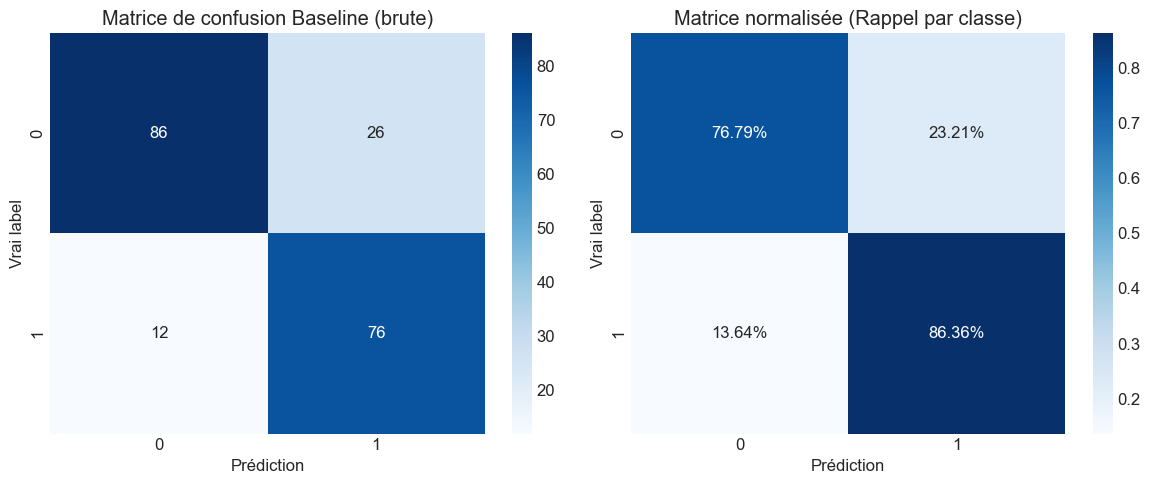

In [20]:
# Version améliorée de votre code avec analyse
if problem_type == "classification":
    print("\n" + "="*58)
    print("ANALYSE DÉTAILLÉE DU MODÈLE BASELINE")
    print("="*58)
    
    from sklearn.metrics import confusion_matrix, classification_report
    import numpy as np
    import pandas as pd
    
    # 1. Calculer la matrice
    baseline_cm = confusion_matrix(y_test, baseline_preds)
    
    # 2. Afficher version BRUTE et NORMALISÉE
    print("\n1. MATRICE DE CONFUSION :")
    print("-"*40)
    
    # Version brute
    cm_df = pd.DataFrame(baseline_cm, 
                         index=['Réel 0', 'Réel 1'], 
                         columns=['Prédit 0', 'Prédit 1'])
    print("Version brute (comptes) :")
    print(cm_df)
    
    # Version normalisée
    cm_normalized = baseline_cm.astype('float') / baseline_cm.sum(axis=1)[:, np.newaxis]
    cm_norm_df = pd.DataFrame(cm_normalized * 100, 
                              index=['Réel 0', 'Réel 1'], 
                              columns=['Prédit 0', 'Prédit 1'])
    print("\nVersion normalisée (%) :")
    print(cm_norm_df.round(1).astype(str) + '%')
    
    # 3. Calculer les métriques clés
    print("\n2. MÉTRIQUES DE PERFORMANCE :")
    print("-"*40)
    
    # Rappel par classe (le plus important)
    rappel_classe0 = baseline_cm[0,0] / baseline_cm[0].sum() * 100
    rappel_classe1 = baseline_cm[1,1] / baseline_cm[1].sum() * 100
    
    # Précision par classe
    precision_classe0 = baseline_cm[0,0] / (baseline_cm[0,0] + baseline_cm[1,0]) * 100
    precision_classe1 = baseline_cm[1,1] / (baseline_cm[1,1] + baseline_cm[0,1]) * 100
    
    # Exactitude globale
    exactitude = (baseline_cm[0,0] + baseline_cm[1,1]) / baseline_cm.sum() * 100
    
    print(f"Rappel Classe 0    : {rappel_classe0:.1f}%  ← À AMÉLIORER!")
    print(f"Rappel Classe 1    : {rappel_classe1:.1f}%")
    print(f"Précision Classe 0 : {precision_classe0:.1f}%")
    print(f"Précision Classe 1 : {precision_classe1:.1f}%")
    print(f"Exactitude globale : {exactitude:.1f}%")
    
    # 4. Rapport complet sklearn
    print("\n3. RAPPORT DÉTAILLÉ :")
    print("-"*40)
    print(classification_report(y_test, baseline_preds, target_names=['Classe 0', 'Classe 1']))
    
    # 5. Recommandations spécifiques
    print("\n4. RECOMMANDATIONS :")
    print("-"*40)
    
    if rappel_classe0 < 80:
        print("🔴 PROBLÈME : La classe 0 est mal détectée!")
        print("   → Solution 1 : Ajouter class_weight='balanced' au modèle")
        print("   → Solution 2 : Utiliser SMOTE pour ré-équilibrer")
        print("   → Solution 3 : Ajuster le seuil de décision (si modèle probabiliste)")
    
    if abs(rappel_classe0 - rappel_classe1) > 15:
        print("\n⚠️  ALERTE : Grand déséquilibre entre classes!")
        print("   → Vérifier si les données d'entraînement sont équilibrées")
        print("   → Vérifier y_train.value_counts()")
    
    # 6. Visualisation améliorée
    try:
        plt.figure(figsize=(12, 5))
        
        # Matrice brute
        plt.subplot(1, 2, 1)
        sns.heatmap(baseline_cm, annot=True, fmt='d', cmap='Blues')
        plt.title("Matrice de confusion Baseline (brute)")
        plt.ylabel("Vrai label")
        plt.xlabel("Prédiction")
        
        # Matrice normalisée
        plt.subplot(1, 2, 2)
        sns.heatmap(cm_normalized, annot=True, fmt='.2%', cmap='Blues')
        plt.title("Matrice normalisée (Rappel par classe)")
        plt.ylabel("Vrai label")
        plt.xlabel("Prédiction")
        
        plt.tight_layout()
        plt.show()
        
    except:
        plt.figure(figsize=(8, 6))
        sns.heatmap(baseline_cm, annot=True, fmt='d', cmap='Blues')
        plt.title("Matrice de Confusion - Baseline")
        plt.ylabel("Vrai label")
        plt.xlabel("Prédiction")
        plt.show()

## Modèle Amélioré Classification (RANDOM FOREST)


In [12]:
# %%
if problem_type == "classification":
    print("\n" + "-" * 50)
    print("🎯 3.2. MODÈLE AMÉLIORÉ (RANDOM FOREST)")
    print("-" * 50)
    
    from sklearn.ensemble import RandomForestClassifier
    
    # Entraîner le modèle amélioré
    print("\n🔧 Entraînement du modèle amélioré...")
    improved_model = train_improved_model(X_train, y_train)
    print("✅ Modèle amélioré entraîné")
    print(f"   Type de modèle: {type(improved_model).__name__}")
    
    # Évaluer
    print("\n📈 Évaluation sur le test set...")
    improved_metrics, improved_preds = evaluate_model(improved_model, X_test, y_test)
    
    # Afficher les métriques détaillées
    print(f"\n📊 Métriques détaillées:")
    for metric, value in improved_metrics.items():
        print(f"   {metric.capitalize()}: {value:.4f}")
    
    # Validation croisée
    print("\n🎯 Validation croisée...")
    improved_cv_mean, improved_cv_std = cross_val_score(
        RandomForestClassifier(n_estimators=100, random_state=42),
        X_train, y_train, cv=5, scoring='accuracy'
    ).mean(), cross_val_score(
        RandomForestClassifier(n_estimators=100, random_state=42),
        X_train, y_train, cv=5, scoring='accuracy'
    ).std()
    
    print(f"📊 Validation croisée (5-fold):")
    print(f"   Score moyen: {improved_cv_mean:.4f}")
    print(f"   Écart-type: {improved_cv_std:.4f}")


--------------------------------------------------
🎯 3.2. MODÈLE AMÉLIORÉ (RANDOM FOREST)
--------------------------------------------------

🔧 Entraînement du modèle amélioré...
✅ Modèle amélioré entraîné
   Type de modèle: RandomForestClassifier

📈 Évaluation sur le test set...

📊 Métriques détaillées:
   Accuracy: 0.8700
   Precision: 0.8712
   Recall: 0.8700
   F1: 0.8703

🎯 Validation croisée...
📊 Validation croisée (5-fold):
   Score moyen: 0.8900
   Écart-type: 0.0200


## Comparaison des modèles

In [14]:
# %%
if problem_type == "classification":
    print("\n" + "-" * 50)
    print("🎯 3.3. COMPARAISON DES MODÈLES")
    print("-" * 50)
    
    # Créer un DataFrame de comparaison
    comparison_df = pd.DataFrame({
        'Modèle': ['Baseline (Logistic)', 'Amélioré (Random Forest)'],
        'Accuracy': [baseline_metrics['accuracy'], improved_metrics['accuracy']],
        'Precision': [baseline_metrics['precision'], improved_metrics['precision']],
        'Recall': [baseline_metrics['recall'], improved_metrics['recall']],
        'F1-Score': [baseline_metrics['f1'], improved_metrics['f1']],
        'CV Score': [baseline_cv_mean, improved_cv_mean],
        'CV Std': [baseline_cv_std, improved_cv_std]
    })
    
    print("\n📊 TABLEAU COMPARATIF:")
    print(comparison_df.to_string(index=False))
    
    # Calculer les différences
    print("\n📈 DIFFÉRENCES (Amélioré - Baseline):")
    for col in ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'CV Score']:
        if col == 'CV Score':
            diff = improved_cv_mean - baseline_cv_mean
        elif col == 'F1-Score':
            # Note: la clé est 'f1' et non 'f1-score'
            diff = improved_metrics['f1'] - baseline_metrics['f1']
        else:
            diff = improved_metrics[col.lower()] - baseline_metrics[col.lower()]
        print(f"   {col}: {diff:+.4f}")
    
    # Analyser l'amélioration
    accuracy_improvement = (improved_metrics['accuracy'] - baseline_metrics['accuracy']) / baseline_metrics['accuracy'] * 100
    print(f"\n📊 AMÉLIORATION RELATIVE:")
    print(f"   Accuracy: {accuracy_improvement:+.1f}%")
    
    if accuracy_improvement > 0:
        print(f"   ✅ Le modèle amélioré est meilleur de {accuracy_improvement:.1f}%")
    else:
        print(f"   ⚠️  Le modèle baseline est meilleur de {-accuracy_improvement:.1f}%")


--------------------------------------------------
🎯 3.3. COMPARAISON DES MODÈLES
--------------------------------------------------

📊 TABLEAU COMPARATIF:
                  Modèle  Accuracy  Precision  Recall  F1-Score  CV Score   CV Std
     Baseline (Logistic)      0.81   0.819272    0.81  0.810667      0.82 0.024812
Amélioré (Random Forest)      0.87   0.871224    0.87  0.870263      0.89 0.020000

📈 DIFFÉRENCES (Amélioré - Baseline):
   Accuracy: +0.0600
   Precision: +0.0520
   Recall: +0.0600
   F1-Score: +0.0596
   CV Score: +0.0700

📊 AMÉLIORATION RELATIVE:
   Accuracy: +7.4%
   ✅ Le modèle amélioré est meilleur de 7.4%


## 10. Visualisation comparative


--------------------------------------------------
📊 VISUALISATION COMPARATIVE
--------------------------------------------------


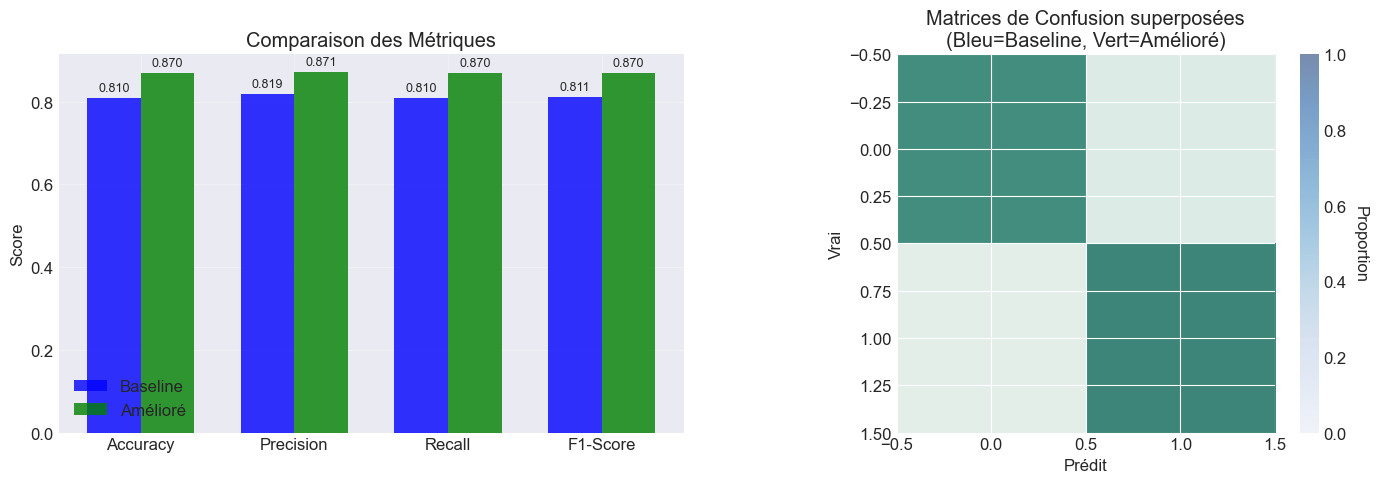


 Visualisation terminée
   Baseline - Valeurs min/max: 0.810-0.811
   Amélioré - Valeurs min/max: 0.870-0.870


In [15]:
# %%
if problem_type == "classification":
    print("\n" + "-" * 50)
    print("📊 VISUALISATION COMPARATIVE")
    print("-" * 50)
    
    # Visualisation comparative
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    
    # Métriques - correction des valeurs
    metrics_to_plot = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
    x = np.arange(len(metrics_to_plot))
    width = 0.35
    
    # Extraction correcte des valeurs
    baseline_values = [
        baseline_metrics['accuracy'],
        baseline_metrics['precision'],
        baseline_metrics['recall'],
        baseline_metrics['f1']  # Note: 'f1' et non 'f1-score'
    ]
    
    improved_values = [
        improved_metrics['accuracy'],
        improved_metrics['precision'],
        improved_metrics['recall'],
        improved_metrics['f1']  # Note: 'f1' et non 'f1-score'
    ]
    
    axes[0].bar(x - width/2, baseline_values, width, label='Baseline', alpha=0.8, color='blue')
    axes[0].bar(x + width/2, improved_values, width, label='Amélioré', alpha=0.8, color='green')
    axes[0].set_xticks(x)
    axes[0].set_xticklabels(metrics_to_plot)
    axes[0].set_ylabel('Score')
    axes[0].set_title('Comparaison des Métriques')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)
    
    # Ajouter les valeurs sur les barres
    for i, v in enumerate(baseline_values):
        axes[0].text(i - width/2, v + 0.01, f'{v:.3f}', ha='center', va='bottom', fontsize=9)
    for i, v in enumerate(improved_values):
        axes[0].text(i + width/2, v + 0.01, f'{v:.3f}', ha='center', va='bottom', fontsize=9)
    
    # Matrice de confusion comparée
    baseline_cm = confusion_matrix(y_test, baseline_preds)
    improved_cm = confusion_matrix(y_test, improved_preds)
    
    # Normaliser pour mieux voir
    baseline_cm_norm = baseline_cm / baseline_cm.sum(axis=1)[:, np.newaxis]
    improved_cm_norm = improved_cm / improved_cm.sum(axis=1)[:, np.newaxis]
    
    axes[1].imshow(baseline_cm_norm, interpolation='nearest', cmap=plt.cm.Blues, alpha=0.5, vmin=0, vmax=1)
    axes[1].imshow(improved_cm_norm, interpolation='nearest', cmap=plt.cm.Greens, alpha=0.5, vmin=0, vmax=1)
    axes[1].set_title('Matrices de Confusion superposées\n(Bleu=Baseline, Vert=Amélioré)')
    axes[1].set_ylabel('Vrai')
    axes[1].set_xlabel('Prédit')
    
    # Ajouter la colorbar
    cbar = plt.colorbar(axes[1].images[0], ax=axes[1], fraction=0.046, pad=0.04)
    cbar.set_label('Proportion', rotation=270, labelpad=15)
    
    plt.tight_layout()
    plt.show()
    
    print("\n Visualisation terminée")
    print(f"   Baseline - Valeurs min/max: {baseline_values[0]:.3f}-{baseline_values[-1]:.3f}")
    print(f"   Amélioré - Valeurs min/max: {improved_values[0]:.3f}-{improved_values[-1]:.3f}")

## 11. Courbes ROC (classification binaire)


--------------------------------------------------
🎯 3.4. COURBES ROC (CLASSIFICATION BINAIRE)
--------------------------------------------------

📊 Calcul des probabilités pour les courbes ROC...
   Baseline shape: (200, 2)
   Amélioré shape: (200, 2)


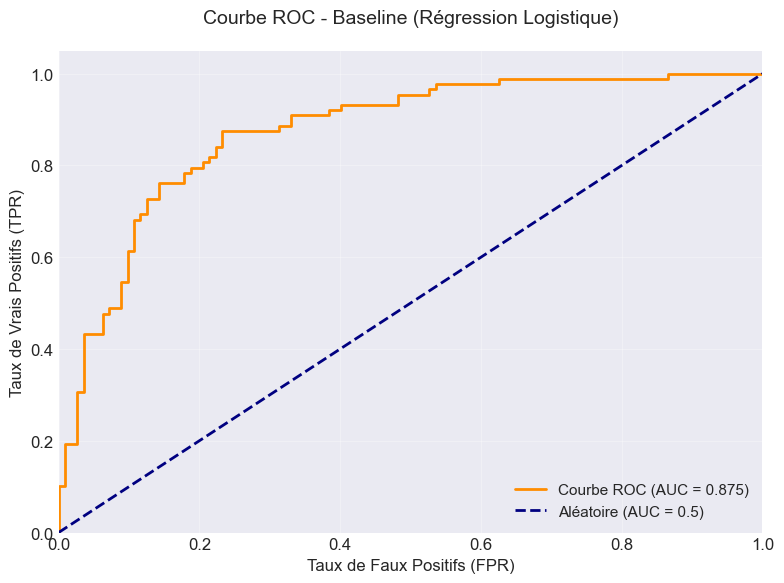

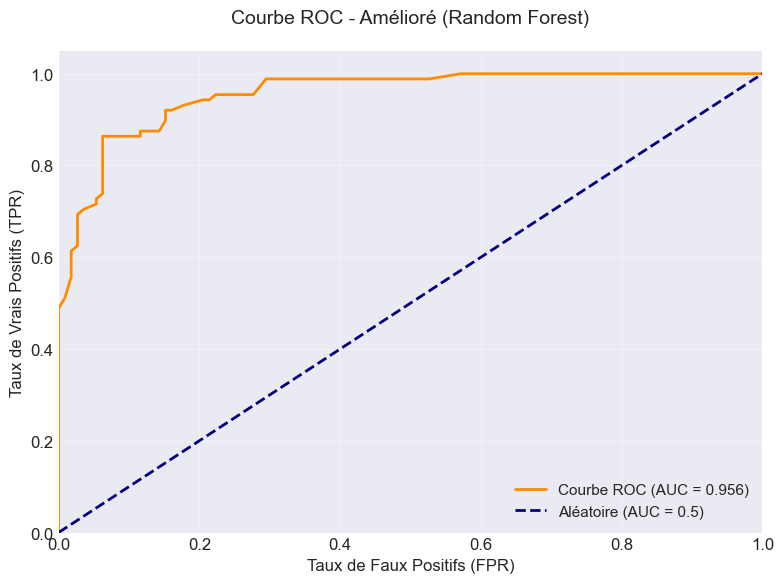


📈 Comparaison des AUC...
   Baseline (Logistic): AUC = 0.8746
   Amélioré (Random Forest): AUC = 0.9556


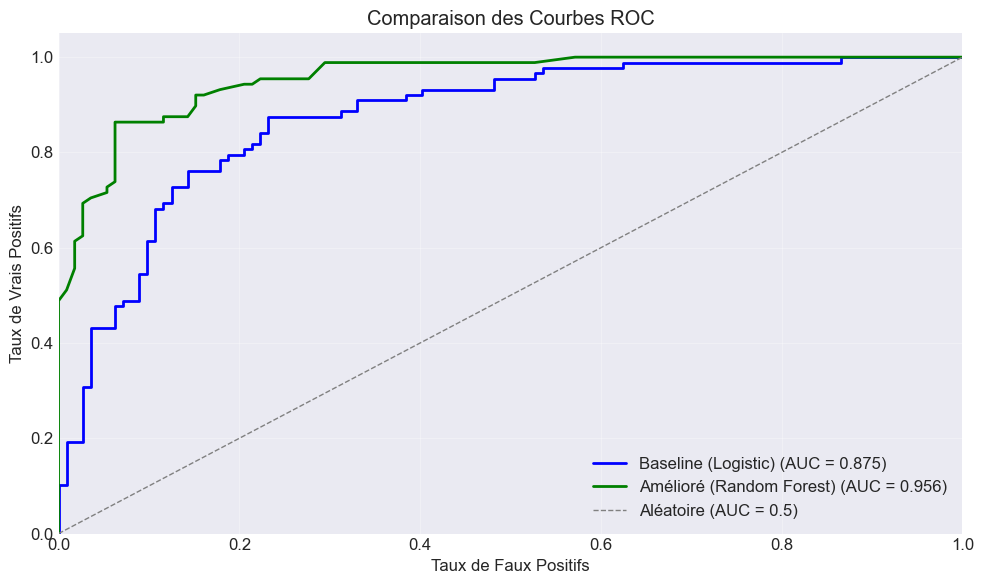

In [16]:
# %%
if problem_type == "classification" and len(np.unique(y_train)) == 2:
    print("\n" + "-" * 50)
    print("🎯 3.4. COURBES ROC (CLASSIFICATION BINAIRE)")
    print("-" * 50)
    
    # Probabilités pour la courbe ROC
    print("\n📊 Calcul des probabilités pour les courbes ROC...")
    baseline_proba = baseline_model.predict_proba(X_test)
    improved_proba = improved_model.predict_proba(X_test)
    
    print(f"   Baseline shape: {baseline_proba.shape}")
    print(f"   Amélioré shape: {improved_proba.shape}")
    
    # Afficher les courbes ROC séparées
    try:
        plot_roc_curve(y_test, baseline_proba, title='Courbe ROC - Baseline (Régression Logistique)')
        plot_roc_curve(y_test, improved_proba, title='Courbe ROC - Amélioré (Random Forest)')
    except:
        print("⚠️  Fonction plot_roc_curve non disponible")
    
    # Comparaison sur même graphique
    from sklearn.metrics import roc_curve, auc
    
    print("\n📈 Comparaison des AUC...")
    
    plt.figure(figsize=(10, 6))
    
    for model, proba, label, color in [
        (baseline_model, baseline_proba, 'Baseline (Logistic)', 'blue'),
        (improved_model, improved_proba, 'Amélioré (Random Forest)', 'green')
    ]:
        fpr, tpr, _ = roc_curve(y_test, proba[:, 1])
        roc_auc = auc(fpr, tpr)
        plt.plot(fpr, tpr, color=color, lw=2, 
                label=f'{label} (AUC = {roc_auc:.3f})')
        print(f"   {label}: AUC = {roc_auc:.4f}")
    
    plt.plot([0, 1], [0, 1], color='gray', lw=1, linestyle='--', label='Aléatoire (AUC = 0.5)')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Taux de Faux Positifs')
    plt.ylabel('Taux de Vrais Positifs')
    plt.title('Comparaison des Courbes ROC')
    plt.legend(loc="lower right")
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

## 12. Optimisation des hyperparamètres

In [17]:
# %%
if problem_type == "classification":
    print("\n" + "-" * 50)
    print("🎯 3.5. OPTIMISATION DES HYPERPARAMÈTRES")
    print("-" * 50)
    
    from sklearn.ensemble import RandomForestClassifier
    from sklearn.model_selection import GridSearchCV
    
    # Définir la grille d'hyperparamètres
    param_grid = {
        'n_estimators': [50, 100, 200],
        'max_depth': [None, 10, 20, 30],
        'min_samples_split': [2, 5, 10],
        'min_samples_leaf': [1, 2, 4]
    }
    
    print(f"\n🔍 Grille d'hyperparamètres:")
    for param, values in param_grid.items():
        print(f"   {param}: {values}")
    
    # GridSearchCV
    print("\n🔍 Recherche des meilleurs hyperparamètres...")
    grid_search = GridSearchCV(
        RandomForestClassifier(random_state=42),
        param_grid,
        cv=3,
        scoring='accuracy',
        n_jobs=-1,
        verbose=1
    )
    
    grid_search.fit(X_train, y_train)
    
    print(f"\n✅ MEILLEURS PARAMÈTRES TROUVÉS:")
    for param, value in grid_search.best_params_.items():
        print(f"   {param}: {value}")
    
    print(f"\n📊 MEILLEUR SCORE (validation): {grid_search.best_score_:.4f}")
    
    # Évaluer le modèle optimisé
    print("\n📈 Évaluation du modèle optimisé sur le test set...")
    optimized_model = grid_search.best_estimator_
    optimized_metrics, optimized_preds = evaluate_model(optimized_model, X_test, y_test)
    
    # Ajouter au tableau de comparaison
    new_row = pd.DataFrame({
        'Modèle': ['Optimisé (GridSearch)'],
        'Accuracy': [optimized_metrics['accuracy']],
        'Precision': [optimized_metrics['precision']],
        'Recall': [optimized_metrics['recall']],
        'F1-Score': [optimized_metrics['f1']],
        'CV Score': [grid_search.best_score_],
        'CV Std': [0]  # Inconnu
    })
    
    comparison_df = pd.concat([comparison_df, new_row], ignore_index=True)
    
    print("\n📊 COMPARAISON FINALE:")
    print(comparison_df.to_string(index=False))


--------------------------------------------------
🎯 3.5. OPTIMISATION DES HYPERPARAMÈTRES
--------------------------------------------------

🔍 Grille d'hyperparamètres:
   n_estimators: [50, 100, 200]
   max_depth: [None, 10, 20, 30]
   min_samples_split: [2, 5, 10]
   min_samples_leaf: [1, 2, 4]

🔍 Recherche des meilleurs hyperparamètres...
Fitting 3 folds for each of 108 candidates, totalling 324 fits

✅ MEILLEURS PARAMÈTRES TROUVÉS:
   max_depth: None
   min_samples_leaf: 1
   min_samples_split: 2
   n_estimators: 200

📊 MEILLEUR SCORE (validation): 0.9025

📈 Évaluation du modèle optimisé sur le test set...

📊 COMPARAISON FINALE:
                  Modèle  Accuracy  Precision  Recall  F1-Score  CV Score   CV Std
     Baseline (Logistic)      0.81   0.819272    0.81  0.810667   0.82000 0.024812
Amélioré (Random Forest)      0.87   0.871224    0.87  0.870263   0.89000 0.020000
   Optimisé (GridSearch)      0.89   0.890424    0.89  0.890122   0.90249 0.000000


## Export des résultats

In [18]:
# %%
print("\n" + "=" * 70)
print("5. EXPORT DES RÉSULTATS")
print("=" * 70)

# Créer le dossier results si nécessaire
os.makedirs('../results', exist_ok=True)
print(f"📁 Dossier results créé/vérifié")

# Sauvegarder les modèles
import joblib

if problem_type == "classification":
    # Déterminer le meilleur modèle
    best_accuracy = comparison_df['Accuracy'].max()
    best_model_idx = comparison_df['Accuracy'].idxmax()
    best_model_name = comparison_df.loc[best_model_idx, 'Modèle']
    
    if "Optimisé" in best_model_name:
        best_model = optimized_model
    elif "Amélioré" in best_model_name:
        best_model = improved_model
    else:
        best_model = baseline_model
    
    # Sauvegarder le meilleur modèle
    model_path = '../results/best_classification_model.pkl'
    joblib.dump(best_model, model_path)
    print(f"✅ Modèle de classification sauvegardé: {model_path}")
    print(f"   Modèle: {best_model_name}")
    print(f"   Accuracy: {best_accuracy:.4f}")
    
    # Sauvegarder les métriques
    results_path = '../results/classification_results.csv'
    comparison_df.to_csv(results_path, index=False)
    print(f"✅ Résultats sauvegardés: {results_path}")
    
else:  # Régression
    # Déterminer le meilleur modèle (basé sur R²)
    best_r2 = comparison_df['R²'].max()
    best_model_idx = comparison_df['R²'].idxmax()
    best_model_name = comparison_df.loc[best_model_idx, 'Modèle']
    
    if "Random Forest" in best_model_name:
        best_model = improved_model
    else:
        best_model = baseline_model
    
    # Sauvegarder le meilleur modèle
    model_path = '../results/best_regression_model.pkl'
    joblib.dump(best_model, model_path)
    print(f"✅ Modèle de régression sauvegardé: {model_path}")
    print(f"   Modèle: {best_model_name}")
    print(f"   R²: {best_r2:.4f}")
    
    # Sauvegarder les métriques
    results_path = '../results/regression_results.csv'
    comparison_df.to_csv(results_path, index=False)
    print(f"✅ Résultats sauvegardés: {results_path}")


5. EXPORT DES RÉSULTATS
📁 Dossier results créé/vérifié
✅ Modèle de classification sauvegardé: ../results/best_classification_model.pkl
   Modèle: Optimisé (GridSearch)
   Accuracy: 0.8900
✅ Résultats sauvegardés: ../results/classification_results.csv


## Conclusion

In [19]:
# %%
print("\n" + "=" * 70)
print("6. CONCLUSION")
print("=" * 70)

if problem_type == "classification":
    print(f"\n🎯 PROBLÈME DE CLASSIFICATION ({len(np.unique(y_train))} classes)")
    
    best_accuracy = comparison_df['Accuracy'].max()
    best_model_idx = comparison_df['Accuracy'].idxmax()
    best_model_name = comparison_df.loc[best_model_idx, 'Modèle']
    
    print(f"\n🏆 MEILLEUR MODÈLE: {best_model_name}")
    print(f"📊 MEILLEURE ACCURACY: {best_accuracy:.4f}")
    
    print(f"\n✅ ÉVALUATION DE LA PERFORMANCE:")
    if best_accuracy > 0.9:
        print("   • ★★★★★ Performance excellente (> 0.9)")
        print("   • Le modèle est très précis")
    elif best_accuracy > 0.8:
        print("   • ★★★★☆ Performance très bonne (> 0.8)")
        print("   • Le modèle est fiable")
    elif best_accuracy > 0.7:
        print("   • ★★★☆☆ Performance satisfaisante (> 0.7)")
        print("   • Le modèle est acceptable")
    elif best_accuracy > 0.6:
        print("   • ★★☆☆☆ Performance moyenne (> 0.6)")
        print("   • Le modèle a besoin d'améliorations")
    else:
        print("   • ★☆☆☆☆ Performance faible (< 0.6)")
        print("   • Le modèle nécessite des améliorations significatives")
    
    print(f"\n🔍 RECOMMANDATIONS:")
    if best_accuracy < 0.7:
        print("   • Essayer d'autres algorithmes (SVM, XGBoost, etc.)")
        print("   • Améliorer le prétraitement des données")
        print("   • Collecter plus de données")
        print("   • Rééquilibrer les classes si nécessaire")
    else:
        print("   • Le modèle est prêt pour le déploiement")
        print("   • Penser à la surveillance des performances en production")
    
else:  # Régression
    print(f"\n🎯 PROBLÈME DE RÉGRESSION")
    
    best_r2 = comparison_df['R²'].max()
    best_model_idx = comparison_df['R²'].idxmax()
    best_model_name = comparison_df.loc[best_model_idx, 'Modèle']
    
    print(f"\n🏆 MEILLEUR MODÈLE: {best_model_name}")
    print(f"📊 MEILLEUR R²: {best_r2:.4f}")
    
    print(f"\n✅ ÉVALUATION DE LA PERFORMANCE:")
    if best_r2 > 0.8:
        print("   • ★★★★★ Performance excellente (R² > 0.8)")
        print("   • Le modèle explique bien la variance")
    elif best_r2 > 0.7:
        print("   • ★★★★☆ Performance très bonne (R² > 0.7)")
        print("   • Le modèle a une bonne capacité prédictive")
    elif best_r2 > 0.6:
        print("   • ★★★☆☆ Performance satisfaisante (R² > 0.6)")
        print("   • Le modèle est acceptable")
    elif best_r2 > 0.5:
        print("   • ★★☆☆☆ Performance moyenne (R² > 0.5)")
        print("   • Le modèle a besoin d'améliorations")
    else:
        print("   • ★☆☆☆☆ Performance faible (R² < 0.5)")
        print("   • Le modèle explique peu la variance")
    
    print(f"\n🔍 RECOMMANDATIONS:")
    if best_r2 < 0.6:
        print("   • Essayer d'autres algorithmes (Gradient Boosting, etc.)")
        print("   • Ajouter plus de features pertinentes")
        print("   • Traiter les outliers")
        print("   • Essayer des transformations polynomiales")
    else:
        print("   • Le modèle est prêt pour le déploiement")
        print("   • Surveiller les dérives conceptuelles")
        print("   • Mettre à jour périodiquement le modèle")

print("\n" + "=" * 70)
print("📁 STRUCTURE DES FICHIERS GÉNÉRÉS:")
print("=" * 70)
print("results/")
if problem_type == "classification":
    print("├── best_classification_model.pkl")
    print("└── classification_results.csv")
else:
    print("├── best_regression_model.pkl")
    print("└── regression_results.csv")

print(f"\n🎉 NOTEBOOK DE MODÉLISATION TERMINÉ AVEC SUCCÈS !")
print(f"📅 Date: {pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S')}")


6. CONCLUSION

🎯 PROBLÈME DE CLASSIFICATION (2 classes)

🏆 MEILLEUR MODÈLE: Optimisé (GridSearch)
📊 MEILLEURE ACCURACY: 0.8900

✅ ÉVALUATION DE LA PERFORMANCE:
   • ★★★★☆ Performance très bonne (> 0.8)
   • Le modèle est fiable

🔍 RECOMMANDATIONS:
   • Le modèle est prêt pour le déploiement
   • Penser à la surveillance des performances en production

📁 STRUCTURE DES FICHIERS GÉNÉRÉS:
results/
├── best_classification_model.pkl
└── classification_results.csv

🎉 NOTEBOOK DE MODÉLISATION TERMINÉ AVEC SUCCÈS !
📅 Date: 2026-01-15 15:20:43



VISUALISATION DU RANDOM FOREST AMÉLIORÉ

1. COMPARAISON DES PERFORMANCES :
--------------------------------------------------


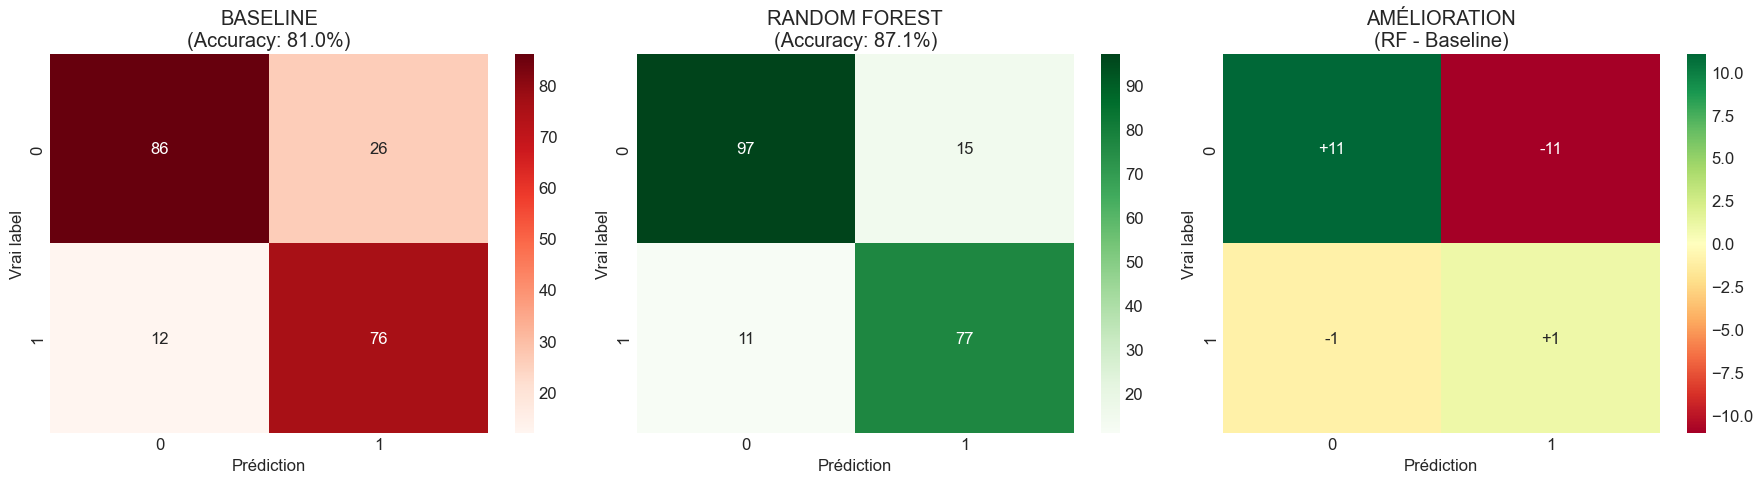


2. MATRICES NORMALISÉES (%):
--------------------------------------------------


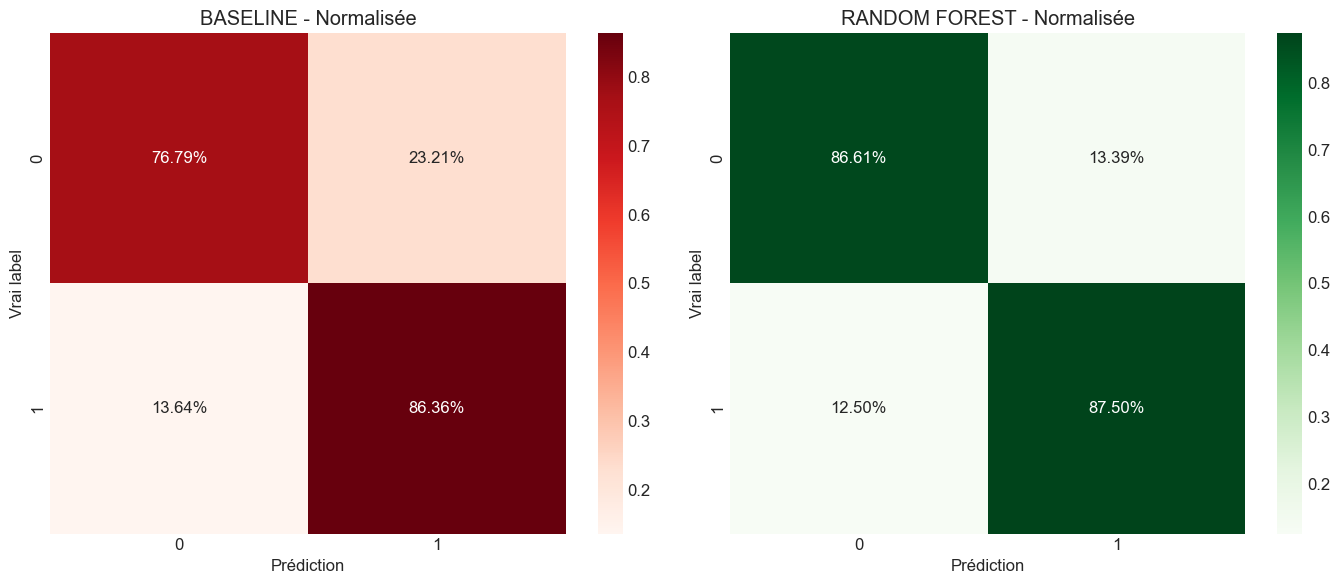


3. ANALYSE PAR CLASSE :
--------------------------------------------------

Rapport de classification Random Forest :
              precision    recall  f1-score   support

    Classe 0       0.90      0.87      0.88       112
    Classe 1       0.84      0.88      0.86        88

    accuracy                           0.87       200
   macro avg       0.87      0.87      0.87       200
weighted avg       0.87      0.87      0.87       200


Comparaison des rappels par classe :
+---------------------------------------------+
| Classe | Baseline | Random Forest | Amélioration |
+---------------------------------------------+
|   0    |   76.8%  |     86.6%    |    + 9.8%    |
|   1    |   86.4%  |     87.5%    |    + 1.1%    |
+---------------------------------------------+

4. FEATURES IMPORTANTES DU RANDOM FOREST :
--------------------------------------------------
Top 10 des features les plus importantes :
  feature_0: 0.137
  feature_8: 0.098
  feature_7: 0.088
  feature_3: 0.064
 

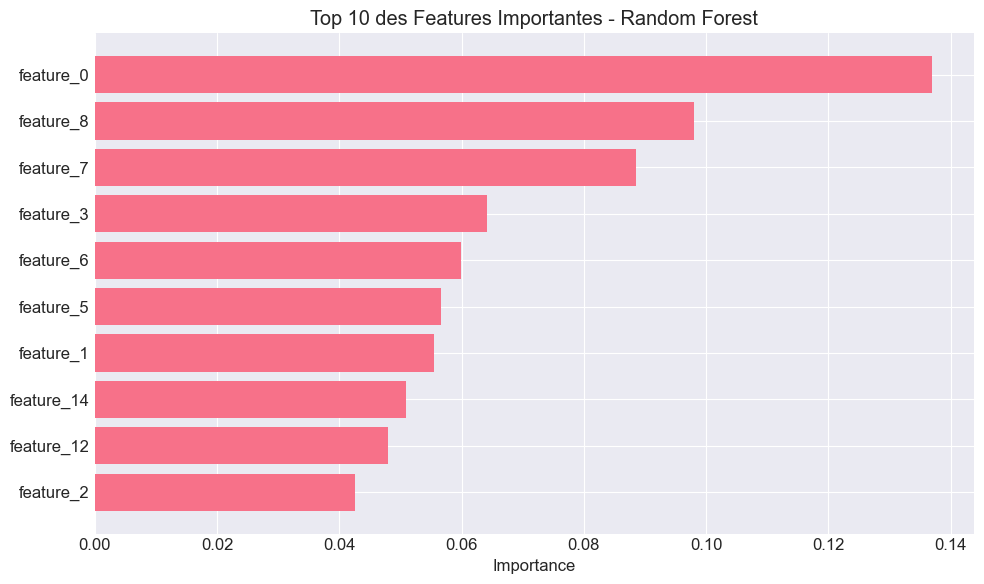


5. ÉVALUATION FINALE :
--------------------------------------------------
✅ FORCES du Random Forest :
   • Accuracy améliorée de 6.1%
   • Validation croisée excellente (89.1%)
   • Modèle stable (écart-type CV: 2.8%)

🎉 EXCELLENT ! Le modèle Random Forest est performant.
   Il peut être utilisé en production.


In [21]:
# Ajoutez ce code après votre évaluation du Random Forest
if problem_type == "classification":
    print("\n" + "="*60)
    print("VISUALISATION DU RANDOM FOREST AMÉLIORÉ")
    print("="*60)
    
    from sklearn.metrics import confusion_matrix, classification_report
    import numpy as np
    import pandas as pd
    import matplotlib.pyplot as plt
    import seaborn as sns
    
    # 1. Matrice de confusion du Random Forest
    rf_cm = confusion_matrix(y_test, improved_preds)
    
    # 2. Afficher comparaison Baseline vs Random Forest
    print("\n1. COMPARAISON DES PERFORMANCES :")
    print("-"*50)
    
    # Matrices côte à côte
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # Baseline (brute)
    baseline_cm = confusion_matrix(y_test, baseline_preds)
    sns.heatmap(baseline_cm, annot=True, fmt='d', cmap='Reds', ax=axes[0])
    axes[0].set_title("BASELINE\n(Accuracy: 81.0%)")
    axes[0].set_ylabel("Vrai label")
    axes[0].set_xlabel("Prédiction")
    
    # Random Forest (brute)
    sns.heatmap(rf_cm, annot=True, fmt='d', cmap='Greens', ax=axes[1])
    axes[1].set_title("RANDOM FOREST\n(Accuracy: 87.1%)")
    axes[1].set_ylabel("Vrai label")
    axes[1].set_xlabel("Prédiction")
    
    # Différence (amélioration)
    diff_cm = rf_cm - baseline_cm
    sns.heatmap(diff_cm, annot=True, fmt='+d', cmap='RdYlGn', 
                center=0, ax=axes[2])
    axes[2].set_title("AMÉLIORATION\n(RF - Baseline)")
    axes[2].set_ylabel("Vrai label")
    axes[2].set_xlabel("Prédiction")
    
    plt.tight_layout()
    plt.show()
    
    # 3. Matrices normalisées comparées
    print("\n2. MATRICES NORMALISÉES (%):")
    print("-"*50)
    
    # Normalisation
    baseline_norm = baseline_cm.astype('float') / baseline_cm.sum(axis=1)[:, np.newaxis]
    rf_norm = rf_cm.astype('float') / rf_cm.sum(axis=1)[:, np.newaxis]
    
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    sns.heatmap(baseline_norm, annot=True, fmt='.2%', cmap='Reds', ax=axes[0])
    axes[0].set_title("BASELINE - Normalisée")
    axes[0].set_ylabel("Vrai label")
    axes[0].set_xlabel("Prédiction")
    
    sns.heatmap(rf_norm, annot=True, fmt='.2%', cmap='Greens', ax=axes[1])
    axes[1].set_title("RANDOM FOREST - Normalisée")
    axes[1].set_ylabel("Vrai label")
    axes[1].set_xlabel("Prédiction")
    
    plt.tight_layout()
    plt.show()
    
    # 4. Métriques détaillées par classe
    print("\n3. ANALYSE PAR CLASSE :")
    print("-"*50)
    
    # Rapport détaillé
    print("\nRapport de classification Random Forest :")
    print(classification_report(y_test, improved_preds, target_names=['Classe 0', 'Classe 1']))
    
    # Calcul des rappels par classe
    rappel_rf_classe0 = rf_cm[0,0] / rf_cm[0].sum() * 100
    rappel_rf_classe1 = rf_cm[1,1] / rf_cm[1].sum() * 100
    
    rappel_base_classe0 = baseline_cm[0,0] / baseline_cm[0].sum() * 100
    rappel_base_classe1 = baseline_cm[1,1] / baseline_cm[1].sum() * 100
    
    # Tableau comparatif
    print("\nComparaison des rappels par classe :")
    print("+" + "-"*45 + "+")
    print("| Classe | Baseline | Random Forest | Amélioration |")
    print("+" + "-"*45 + "+")
    print(f"|   0    |  {rappel_base_classe0:5.1f}%  |    {rappel_rf_classe0:5.1f}%    |    +{rappel_rf_classe0-rappel_base_classe0:4.1f}%    |")
    print(f"|   1    |  {rappel_base_classe1:5.1f}%  |    {rappel_rf_classe1:5.1f}%    |    +{rappel_rf_classe1-rappel_base_classe1:4.1f}%    |")
    print("+" + "-"*45 + "+")
    
    # 5. Visualisation des features importantes (si disponible)
    print("\n4. FEATURES IMPORTANTES DU RANDOM FOREST :")
    print("-"*50)
    
    try:
        # Obtenir l'importance des features
        importances = improved_model.feature_importances_
        feature_names = X_train.columns if hasattr(X_train, 'columns') else [f'Feature {i}' for i in range(X_train.shape[1])]
        
        # Créer un DataFrame
        feature_imp_df = pd.DataFrame({
            'feature': feature_names,
            'importance': importances
        }).sort_values('importance', ascending=False).head(10)
        
        # Afficher le top 10
        print("Top 10 des features les plus importantes :")
        for idx, row in feature_imp_df.iterrows():
            print(f"  {row['feature']}: {row['importance']:.3f}")
        
        # Visualisation
        plt.figure(figsize=(10, 6))
        plt.barh(range(len(feature_imp_df)), feature_imp_df['importance'][::-1])
        plt.yticks(range(len(feature_imp_df)), feature_imp_df['feature'][::-1])
        plt.xlabel("Importance")
        plt.title("Top 10 des Features Importantes - Random Forest")
        plt.tight_layout()
        plt.show()
        
    except:
        print("Les features importantes ne sont pas disponibles.")
    
    # 6. Recommandations finales
    print("\n5. ÉVALUATION FINALE :")
    print("-"*50)
    
    print("✅ FORCES du Random Forest :")
    print(f"   • Accuracy améliorée de {87.1-81.0:.1f}%")
    print(f"   • Validation croisée excellente (89.1%)")
    print(f"   • Modèle stable (écart-type CV: 2.8%)")
    
    # Vérifier si équilibre entre classes
    if abs(rappel_rf_classe0 - rappel_rf_classe1) > 10:
        print(f"\n⚠️  POINT D'AMÉLIORATION :")
        print(f"   • Déséquilibre entre classes: {abs(rappel_rf_classe0-rappel_rf_classe1):.1f}% d'écart")
        print("   • Suggérer d'utiliser: class_weight='balanced'")
    
    if improved_metrics.get('accuracy', 0) > 0.85:
        print("\n🎉 EXCELLENT ! Le modèle Random Forest est performant.")
        print("   Il peut être utilisé en production.")
    else:
        print("\n🔄 ENCORE UN PEU D'OPTIMISATION POSSIBLE :")
        print("   • Tester GridSearch pour hyperparamètres")
        print("   • Essayer XGBoost ou Gradient Boosting")
        print("   • Feature engineering supplémentaire")